# Lending Club Dataset from 2007 to 2018

In [ ]:
!pip install optuna optuna-integration
!pip install category-encoders
!pip install catboost
!pip install cuml-cu12 --extra-index-url=https://pypi.nvidia.com
!pip install xgboost>=2.0 cudf-cu12 --extra-index-url=https://pypi.nvidia.com

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import polars as pl
import polars.selectors as cs
import cupy as cp

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')

# Clustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder, TargetEncoder
from sklearn.model_selection import RepeatedStratifiedKFold
from category_encoders import CatBoostEncoder, WOEEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from cuml.cluster import KMeans as cuMLKMeans

# GPU models
from cuml.linear_model import LogisticRegression as cuLR
from cuml.ensemble import RandomForestClassifier as cuRF
from cuml.preprocessing import StandardScaler as cuStandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Calibration
from sklearn.calibration import CalibratedClassifierCV
from sklearn.isotonic import IsotonicRegression

# Metrics
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    precision_recall_curve
)

# Optuna
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

# SHAP
import shap

print('All imports OK')

All imports OK


In [ ]:
def csv_to_parquet(path):
    # Read CSV with Polars
    df = pl.read_csv(path, infer_schema_length=10000,
    # null_values=["NA", "n/a", "N/A", ""],
    ignore_errors=True)
    # Save to Parquet on Drive immediately
    parquet_path = path.replace(".csv", ".parquet")
    df.write_parquet(
    parquet_path,
    compression="snappy")

In [ ]:
# Never use CSV again
accepted_df = pl.read_parquet(
    "../data/processed_data/processed_accepted_df.parquet.csv"
)
accepted_df.head()

id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,…,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
i64,str,f64,f64,f64,str,f64,f64,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,f64,f64,str,f64,f64,f64,str,str,str,str,str,f64,f64,f64
68407277,null,3600.0,3600.0,3600.0,""" 36 months""",13.99,123.03,"""C""","""C4""","""leadman""","""10+ years""","""MORTGAGE""",55000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""debt_consolidation""","""Debt consolidation""","""190xx""","""PA""",5.91,0.0,"""Aug-2003""",675.0,679.0,1.0,30.0,null,7.0,0.0,2765.0,29.7,13.0,…,13734.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
68355089,null,24700.0,24700.0,24700.0,""" 36 months""",11.99,820.28,"""C""","""C1""","""Engineer""","""10+ years""","""MORTGAGE""",65000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""small_business""","""Business""","""577xx""","""SD""",16.06,1.0,"""Dec-1999""",715.0,719.0,4.0,6.0,null,22.0,0.0,21470.0,19.2,38.0,…,24667.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
68341763,null,20000.0,20000.0,20000.0,""" 60 months""",10.78,432.66,"""B""","""B4""","""truck driver""","""10+ years""","""MORTGAGE""",63000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""home_improvement""",null,"""605xx""","""IL""",10.78,0.0,"""Aug-2000""",695.0,699.0,0.0,null,null,6.0,0.0,7869.0,56.2,18.0,…,14877.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
66310712,null,35000.0,35000.0,35000.0,""" 60 months""",14.85,829.9,"""C""","""C5""","""Information Systems Officer""","""10+ years""","""MORTGAGE""",110000.0,"""Source Verified""","""Dec-2015""","""Current""","""n""","""https://lendingclub.com/browse…",null,"""debt_consolidation""","""Debt consolidation""","""076xx""","""NJ""",17.06,0.0,"""Sep-2008""",785.0,789.0,0.0,null,null,13.0,0.0,7802.0,11.6,17.0,…,18000.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
68476807,null,10400.0,10400.0,10400.0,""" 60 months""",22.45,289.91,"""F""","""F1""","""Contract Specialist""","""3 years""","""MORTGAGE""",104433.0,"""Source

## CatBoostEncoder

In [ ]:
def generate_oof_encoding(
    X_train, y_train, X_val, X_test,
    cat_cols, encoder_type, cv=None
):
    if cv is None:
        cv = RepeatedStratifiedKFold(
            n_splits=5, n_repeats=5, random_state=42
        )

    X_train_enc = X_train.copy()
    X_val_enc   = X_val.copy()
    X_test_enc  = X_test.copy()

    # ---------------------------------------------------------
    # Stage 1: OOF encoding for train
    # ---------------------------------------------------------
    oof_parts = []

    for train_idx, fold_idx in cv.split(X_train, y_train):
        X_fold_tr  = X_train.iloc[train_idx]
        y_fold_tr  = y_train.iloc[train_idx]
        X_fold_val = X_train.iloc[fold_idx]

        # Fit on this fold's train subset only
        encoder = encoder_type(cols=cat_cols)
        encoder.fit(X_fold_tr[cat_cols], y_fold_tr)

        # Encode the held-out fold slice
        fold_encoded = encoder.transform(X_fold_val[cat_cols])
        # preserve original row index
        fold_encoded.index = X_fold_val.index
        oof_parts.append(fold_encoded)

    # Concatenate all fold slices and sort back to original row order
    oof_encoded = (
        pd.concat(oof_parts)
        .groupby(level=0)
        .mean()
        .reindex(X_train.index)
    )

    # Replace cat columns in train with the OOF-encoded values
    X_train_enc[cat_cols] = oof_encoded[cat_cols].values

    # ---------------------------------------------------------
    # Stage 2: Final encoder on all train → transform val and test
    # ---------------------------------------------------------
    final_encoder = encoder_type(cols=cat_cols)
    final_encoder.fit(X_train[cat_cols], y_train)

    X_val_enc[cat_cols]  = final_encoder.transform(X_val[cat_cols])
    X_test_enc[cat_cols] = final_encoder.transform(X_test[cat_cols])

    return X_train_enc, X_val_enc, X_test_enc

In [ ]:
def time_based_split(X: pl.DataFrame, y: pl.Series,
                     split_date: str = "2016-01-01",
                     seed: int = 42):
    assert 'issue_d' in X.columns, 'issue_d column required'

    split_dt = pl.lit(split_date).str.to_date('%Y-%m-%d')

    temp_df = X.with_columns(
    pl.col('issue_d').str.to_date('%b-%Y') if X['issue_d'].dtype == pl.Utf8
    else pl.col('issue_d'),
    target=y
)

    train_pool_df = temp_df.filter(pl.col('issue_d') < split_dt)
    test_df = temp_df.filter(pl.col('issue_d') >= split_dt)

    # Shuffle train pool and take val data same size as text
    val_prop = len(test_df) / len(train_pool_df)
    train_pool_df = train_pool_df.sample(fraction=1.0, shuffle=True, seed=seed)
    # val length == test length
    n_val    = len(test_df)  # val length == test length
    val_df   = train_pool_df.slice(len(train_pool_df) - n_val, n_val)
    train_df = train_pool_df.slice(0, len(train_pool_df) - n_val)

    y_train = train_df['target']
    y_val   = val_df['target']
    y_test  = test_df['target']

    X_train = train_df.drop(['target', 'issue_d', 'earliest_cr_line'])
    X_val   = val_df.drop(['target', 'issue_d', 'earliest_cr_line'])
    X_test  = test_df.drop(['target', 'issue_d', 'earliest_cr_line'])

    print(f"Train: {len(X_train):,} rows")
    print(f"Val: {len(X_val):,} rows  (== Test: {len(X_test):,} rows)")
    print(f"Test: {len(X_test):,} rows")

    return X_train, X_val, X_test, y_train, y_val, y_test


def stratified_kfold_split(model, X: np.ndarray, y: np.ndarray, n_splits=5) -> float:
    """
    Evaluates a model using Stratified K-Fold. Returns mean F1 score.
    """
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    fold_scores = []

    for train_idx, valid_idx in skf.split(X, y):
        X_tr, X_va = X[train_idx], X[valid_idx]
        y_tr, y_va = y[train_idx], y[valid_idx]

        # Fit model
        model.fit(X_tr, y_tr)

        # Predict
        preds = model.predict(X_va)
        fold_scores.append(f1_score(y_va, preds))

    return np.mean(fold_scores)

## Step 1: Split and Encoding

In [ ]:
X = accepted_df.drop('target')
y = accepted_df['target']

assert len(X) == len(y)
print(f'Encoded X: {X.shape}  |  Default rate: {y.mean()*100:.2f}%')
print(X.schema)

Encoded X: (1277783, 40)  |  Default rate: 20.21%
Schema({'term': Int16, 'int_rate': Float64, 'grade': String, 'sub_grade': Int8, 'purpose': String, 'emp_length': Float64, 'home_ownership': String, 'dti': Float64, 'fico_range_low': Float64, 'earliest_cr_line': Date, 'open_acc': Float64, 'total_acc': Float64, 'mort_acc': Float64, 'tot_cur_bal': Float64, 'revol_bal': Float64, 'revol_util': Float64, 'bc_util': Float64, 'percent_bc_gt_75': Float64, 'inq_last_6mths': Float64, 'issue_d': Date, 'is_ten_plus_years': Int8, 'loan_to_income': Float64, 'inquiries_per_account': Float64, 'active_accounts_ratio': Float64, 'revolbal_to_income': Float64, 'credit_history_years': Float64, 'payment_to_income': Float64, 'revol_stress': Float64, 'total_interest_burden': Float64, 'total_red_flags': Int32, 'annual_inc_arithmetic': Categorical, 'loan_amnt_arithmetic': Categorical, 'annual_inc_quantile': Categorical, 'loan_amnt_quantile': Categorical, 'annual_inc_uniform': String, 'loan_amnt_uniform': String, '

In [ ]:
X_train_pl, X_val_pl, X_test_pl, \
y_train_pl, y_val_pl, y_test_pl = time_based_split(X, y, split_date="2016-01-01")

# Convert to Pandas
X_train_pd = X_train_pl.to_pandas()
X_val_pd   = X_val_pl.to_pandas()
X_test_pd  = X_test_pl.to_pandas()
y_train_pd = y_train_pl.to_pandas()
y_val_pd   = y_val_pl.to_pandas()
y_test_pd  = y_test_pl.to_pandas()

Train: 240,371 rows
Val: 518,706 rows  (== Test: 518,706 rows)
Test: 518,706 rows


In [ ]:
# Define the categorical columns
cat_cols = [
    'home_ownership', 'grade', 'purpose',
    'annual_inc_arithmetic', 'loan_amnt_arithmetic',
    'annual_inc_quantile', 'loan_amnt_quantile',
    'annual_inc_uniform', 'loan_amnt_uniform'
]

In [ ]:
X_train_pd, X_val_pd, X_test_pd = generate_oof_encoding(
    X_train=X_train_pd, y_train=y_train_pd,
    X_val=X_val_pd, X_test=X_test_pd,
    cat_cols=cat_cols, encoder_type=CatBoostEncoder
)

In [ ]:
feature_names = X_train_pd.columns.tolist()

# Numpy
X_train_np = X_train_pd.to_numpy().astype(np.float32)
X_val_np   = X_val_pd.to_numpy().astype(np.float32)
X_test_np  = X_test_pd.to_numpy().astype(np.float32)
y_train_np = y_train_pl.to_numpy().astype(np.float32)
y_val_np   = y_val_pl.to_numpy().astype(np.float32)
y_test_np  = y_test_pl.to_numpy().astype(np.float32)

# GPU arrays for cuML
X_train_gpu = cp.asarray(X_train_pd.to_numpy(), dtype=cp.float32)
X_val_gpu   = cp.asarray(X_val_pd.to_numpy(),   dtype=cp.float32)
X_test_gpu  = cp.asarray(X_test_pd.to_numpy(),  dtype=cp.float32)
y_train_gpu = cp.asarray(y_train_np)
y_val_gpu   = cp.asarray(y_val_np)
y_test_gpu  = cp.asarray(y_test_np)

# Imbalance ratio — computed from train only
neg, pos        = (y_train_np == 0).sum(), (y_train_np == 1).sum()
imbalance_ratio = neg / pos
print(f"Imbalance ratio (neg/pos): {imbalance_ratio:.2f}")
print(f"Feature count: {len(feature_names)}")

Imbalance ratio (neg/pos): 4.35
Feature count: 38


In [ ]:
def to_np(arr):
    """Convert cupy to numpy"""
    return arr.get() if isinstance(arr, cp.ndarray) else np.asarray(arr)

## K-Means clustering

In [ ]:
from cuml.cluster import KMeans
from sklearn.cluster import MiniBatchKMeans
from cuml.linear_model import LogisticRegression

In [ ]:
#  Separate features and target
print(f"Final feature matrix : {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Default rate: {y.mean()*100:.2f}%")

Final feature matrix : (1277783, 40)
Target shape: (1277783,)
Default rate: 20.21%


In [ ]:
# Input features for RL model
features = ['total_interest_burden', 'grade', 'fico_range_low', 'payment_to_income', 'dti']
# Select features from clean_df
state_df = clean_df.select(features).clone().drop_nulls()
# Convert to Pandas DataFrame to use sklearn
state_pd_df = state_df.to_pandas()
# Encode 'grade' using LabelEncoder
le_grade = LabelEncoder()
state_pd_df['grade'] = le_grade.fit_transform(state_pd_df['grade'])
# Scale numeric features
scaler = StandardScaler()
# Apply scaler to all columns of the Pandas DataFrame
scaled_state_df = scaler.fit_transform(state_pd_df)
# Convert to CuPy for cuML
state_gpu_df = cp.asarray(scaled_state_df)

# Find K
inertia = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = MiniBatchKMeans(
        n_clusters=k, init="k-means++",
        random_state=42, batch_size=15000
    )
    labels = kmeans.fit_predict(scaled_state_df)
    # get labels for silhouette score on CPU
    inertia.append(float(kmeans.inertia_))
    silhouette_scores.append(
        silhouette_score(state_pd_df, labels, sample_size=30000, random_state=42)
    )
    print(f'End{k} iteration')


End2 iteration
End3 iteration
End4 iteration
End5 iteration
End6 iteration
End7 iteration
End8 iteration
End9 iteration
End10 iteration


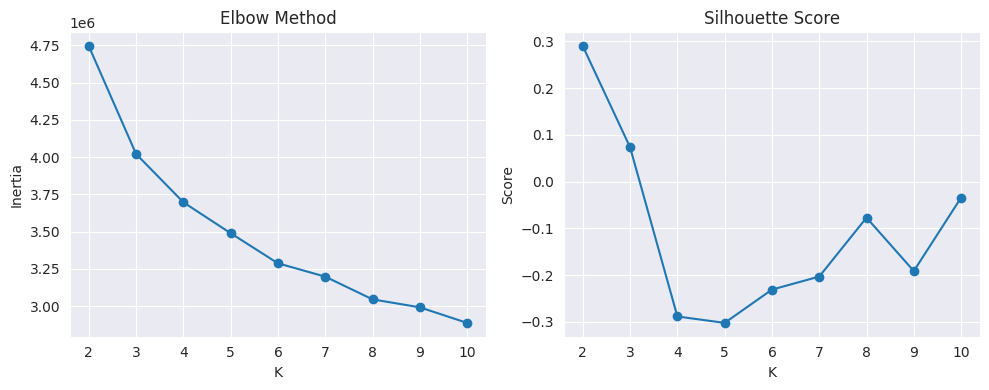

Optimal K: 2


In [ ]:
# --- Plot Elbow ---
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(K_range, inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("K")
plt.ylabel("Inertia")

# --- Plot Silhouette ---
plt.subplot(1,2,2)
plt.plot(K_range, silhouette_scores, marker='o')
plt.title("Silhouette Score")
plt.xlabel("K")
plt.ylabel("Score")

plt.tight_layout()
plt.show()

# Choose optimal K that gets max silhouette
optimal_k = K_range[np.argmax(silhouette_scores)]
print("Optimal K:", optimal_k)

### PCA of Best K

In [ ]:
# Model (k=6)
print(f"Training final model with K={optimal_k} on full dataset...")
final_kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    random_state=42,
    n_init=1
)
labels = final_kmeans.fit_predict(state_gpu_df)
labels_np = labels.get()

# inertia and silhouette metrics
inertia = final_kmeans.inertia_
silhouette = silhouette_score(state_pd_df, labels_np)

Training final model with K=2 on full dataset...


In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(scaled_state_df)

# Assign pca values and cluster
state_pd_df['pca1'] = X_pca[:,0]
state_pd_df['pca2'] = X_pca[:,1]
state_pd_df["cluster"] = labels_np

plt.figure(figsize=(8,6))
sns.scatterplot(
    x='pca1', y='pca2',
    hue='cluster',
    palette='tab10',
    data=state_pd_df,
    alpha=0.6
)
plt.title("PCA Visualization of Clusters")
plt.show()

# CENTROID ANALYSIS
centers_np = final_kmeans.cluster_centers_.get()
centroids = pd.DataFrame(
    scaler.inverse_transform(centers_np),
    columns=features
)
print("\nCluster Centroids (Original Scale):\n", centroids)

In [ ]:
# Model (k4)
print(f"Training final model with K= 4 on full dataset...")
final_kmeans = KMeans(
    n_clusters=4,
    init="k-means++",
    random_state=42,
    n_init=1
)
labels = final_kmeans.fit_predict(state_gpu_df)
labels_np = labels.get()

# inertia and silhouette metrics
inertia = final_kmeans.inertia_
silhouette = silhouette_score(state_pd_df, labels_np)

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(scaled_state_df)

# Assign pca values and cluster
state_pd_df['pca1'] = X_pca[:,0]
state_pd_df['pca2'] = X_pca[:,1]
state_pd_df["cluster"] = labels_np

plt.figure(figsize=(8,6))
sns.scatterplot(
    x='pca1', y='pca2',
    hue='cluster',
    palette='tab10',
    data=state_pd_df,
    alpha=0.6
)
plt.title("PCA Visualization of Clusters")
plt.show()

# CENTROID ANALYSIS
centers_np = final_kmeans.cluster_centers_.get()
centroids = pd.DataFrame(
    scaler.inverse_transform(centers_np),
    columns=features
)
print("\nCluster Centroids (Original Scale):\n", centroids)